# Exercise 1: Multi-Layer Perceptron (MLP) Classifier

**Module:** PUSL3123 AI and Machine Learning | **Dataset:** CIFAR-10  
**Aim:** Implement and train an MLP with three trainable layers on CIFAR-10 and evaluate training, validation and official test performance.

**Requirements:** Python 3.9+, `torch`, `torchvision`, `numpy`, `pandas`, `matplotlib`, `jupyter`  
(`pip install torch torchvision numpy pandas matplotlib jupyter`)

**How to reproduce:** run all cells from top to bottom (Kernel > Restart & Run All). CIFAR-10 downloads automatically to `./data`. A fixed seed (42), an 80:20 train/validation split of the official training set, and identical settings (batch size 128, 10 epochs, Adam, lr 1e-3) are used throughout. The official test set is never used for training, tuning or model selection.

In [1]:
# ==== Exercise 1: MLP classifier on CIFAR-10 ====
# Requirements: torch, torchvision, pandas, matplotlib
# Run all cells top to bottom. The test set is used only for final evaluation.

import random, time
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms

# ---- Configuration (keep identical in all four notebooks) ----
SEED = 42
BATCH_SIZE = 128
EPOCHS = 10
LEARNING_RATE = 1e-3
NUM_WORKERS = 0
DATA_DIR = "./data"
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def set_seed(seed=SEED):
    """Make weight initialisation and shuffling reproducible."""
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed()

# ---- Data preparation ----
mean = (0.4914, 0.4822, 0.4465)   # CIFAR-10 channel means
std = (0.2470, 0.2435, 0.2616)    # CIFAR-10 channel standard deviations
transform = transforms.Compose([transforms.ToTensor(), transforms.Normalize(mean, std)])

full_train = datasets.CIFAR10(DATA_DIR, train=True, download=True, transform=transform)
test_set = datasets.CIFAR10(DATA_DIR, train=False, download=True, transform=transform)

# One reproducible 80:20 train/validation split of the official training set
train_size = int(0.8 * len(full_train))
val_size = len(full_train) - train_size
train_set, val_set = random_split(full_train, [train_size, val_size],
                                  generator=torch.Generator().manual_seed(SEED))

train_loader = DataLoader(train_set, BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS)
val_loader = DataLoader(val_set, BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)
test_loader = DataLoader(test_set, BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)
print(f"Device: {DEVICE} | Train: {len(train_set)} | Val: {len(val_set)} | Test: {len(test_set)}")

100.0%


Device: cpu | Train: 40000 | Val: 10000 | Test: 10000


In [2]:
# ==== Model: three trainable layers (Linear -> Linear -> Linear) ====
class MLPClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.network = nn.Sequential(
            nn.Flatten(),                 # 3x32x32 image -> 3072-vector (spatial layout is discarded)
            nn.Linear(3 * 32 * 32, 512), nn.ReLU(),
            nn.Linear(512, 256), nn.ReLU(),
            nn.Linear(256, 10),           # raw logits; CrossEntropyLoss applies softmax
        )
    def forward(self, x):
        return self.network(x)

In [3]:
# ==== Training and evaluation helpers ====
def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

def run_epoch(model, loader, criterion, optimizer=None):
    """One pass over loader. Trains if an optimizer is given, otherwise evaluates."""
    training = optimizer is not None
    model.train() if training else model.eval()
    total_loss, correct, total = 0.0, 0, 0
    with torch.set_grad_enabled(training):
        for images, labels in loader:
            images, labels = images.to(DEVICE), labels.to(DEVICE)
            if training:
                optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            if training:
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * labels.size(0)
            correct += (outputs.argmax(1) == labels).sum().item()
            total += labels.size(0)
    return total_loss / total, correct / total

def train_model(model, train_dl, val_dl, epochs=EPOCHS, lr=LEARNING_RATE):
    model = model.to(DEVICE)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)
    hist = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    for epoch in range(epochs):
        start = time.time()
        tl, ta = run_epoch(model, train_dl, criterion, optimizer)
        vl, va = run_epoch(model, val_dl, criterion)
        for k, v in zip(hist, (tl, vl, ta, va)):
            hist[k].append(v)
        print(f"Epoch {epoch+1:02d}/{epochs} | train loss {tl:.4f} acc {ta:.4f} | "
              f"val loss {vl:.4f} acc {va:.4f} | {time.time()-start:.1f}s")
    return model, hist

def evaluate_model(model, loader, label):
    loss, acc = run_epoch(model, loader, nn.CrossEntropyLoss())
    print(f"{label}: loss={loss:.4f}, accuracy={acc*100:.2f}%")
    return loss, acc

def plot_history(hist, title):
    ep = range(1, len(hist["train_loss"]) + 1)
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].plot(ep, hist["train_loss"], "o-", label="Training")
    ax[0].plot(ep, hist["val_loss"], "o-", label="Validation")
    ax[0].set(title="Loss", xlabel="Epoch", ylabel="Cross-entropy loss"); ax[0].legend(); ax[0].grid(alpha=.3)
    ax[1].plot(ep, hist["train_acc"], "o-", label="Training")
    ax[1].plot(ep, hist["val_acc"], "o-", label="Validation")
    ax[1].set(title="Accuracy", xlabel="Epoch", ylabel="Accuracy"); ax[1].legend(); ax[1].grid(alpha=.3)
    fig.suptitle(title); plt.tight_layout(); plt.show()

MLPClassifier(
  (network): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=3072, out_features=512, bias=True)
    (2): ReLU()
    (3): Linear(in_features=512, out_features=256, bias=True)
    (4): ReLU()
    (5): Linear(in_features=256, out_features=10, bias=True)
  )
)
Trainable parameters: 1,707,274
Epoch 01/10 | train loss 1.6727 acc 0.4078 | val loss 1.5451 acc 0.4611 | 11.7s
Epoch 02/10 | train loss 1.4586 acc 0.4872 | val loss 1.4626 acc 0.4925 | 13.5s
Epoch 03/10 | train loss 1.3439 acc 0.5261 | val loss 1.4216 acc 0.5017 | 12.6s
Epoch 04/10 | train loss 1.2532 acc 0.5574 | val loss 1.3852 acc 0.5200 | 12.6s
Epoch 05/10 | train loss 1.1676 acc 0.5857 | val loss 1.4251 acc 0.5192 | 12.7s
Epoch 06/10 | train loss 1.0922 acc 0.6138 | val loss 1.4064 acc 0.5235 | 12.7s
Epoch 07/10 | train loss 1.0230 acc 0.6385 | val loss 1.4164 acc 0.5278 | 12.6s
Epoch 08/10 | train loss 0.9350 acc 0.6669 | val loss 1.4921 acc 0.5185 | 12.8s
Epoch 09/10 | train lo

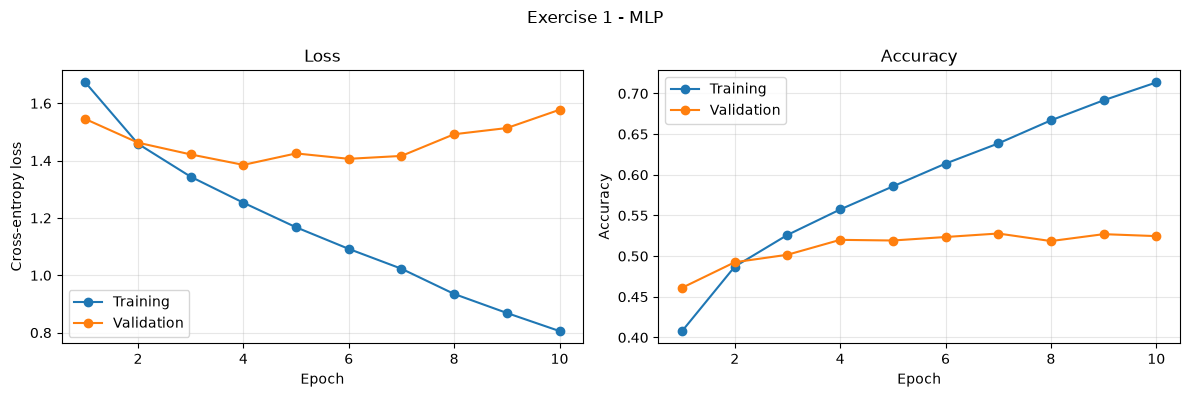

Lowest validation loss at epoch 4


In [4]:
# ==== Train the MLP ====
set_seed()
mlp_model = MLPClassifier()
print(mlp_model)
print(f"Trainable parameters: {count_parameters(mlp_model):,}")
mlp_model, mlp_history = train_model(mlp_model, train_loader, val_loader)
plot_history(mlp_history, "Exercise 1 - MLP")

best_epoch = int(np.argmin(mlp_history["val_loss"])) + 1
print(f"Lowest validation loss at epoch {best_epoch}")

In [5]:
# ==== Final evaluation (test set is NOT used for any model choice) ====
train_loss, train_acc = evaluate_model(mlp_model, train_loader, "Training")
val_loss, val_acc = evaluate_model(mlp_model, val_loader, "Validation")
test_loss, test_acc = evaluate_model(mlp_model, test_loader, "Official test")
print(f"\nTrain-test accuracy gap: {(train_acc - test_acc)*100:.2f} percentage points")
torch.save(mlp_model.state_dict(), "exercise1_mlp_cifar10.pth")

Training: loss=0.6769, accuracy=76.38%
Validation: loss=1.5774, accuracy=52.46%
Official test: loss=1.5990, accuracy=52.40%

Train-test accuracy gap: 23.98 percentage points
